# fetch 재연결과 오류 이벤트

**이 노트북에서 할 일**

1. 요청 머리 `Last-Event-ID`에 마지막으로 받은 사건 번호를 적어, 그다음 사건부터 이어 받습니다.
2. 시간 제한을 0초로 바꾼 응답에서, 상태 코드만 보는 판정이 놓치는 것을 봅니다.
3. 마지막 SSE 사건의 이름이 `done`인지 보는 판정으로 고칩니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램을 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
앞 절에서 배운 함수 넷은 도구 파일 `serve_tools.py`에서 가져옵니다.
TS 파일 `client/stream.ts`는 글로 읽기만 하고, 이 노트북에서 실행하지 않습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽고, 5절과 6절의 Before·After를 함께 봅니다.
7절은 넣는 값 하나를 바꿔 보는 실습이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 노란 상자 첫 응답에서 앞 사건 둘을 받음 sse-1:0과 sse-1:1에서, 파란 상자 끊겼다고 보고 마지막 사건 번호 sse-1:1을 기억으로 갑니다. 이어서 초록 상자 다시 보낸 요청 요청 머리 Last-Event-ID sse-1:1, 초록 상자 제공 함수 get_resume_index 다음 자리부터 보내게 함, 초록 상자 그래프를 처음부터 다시 실행 앞 자리 둘은 건너뜀을 지납니다. 마지막으로 노란 상자 다시 받은 사건 sse-1:2부터 sse-1:5와 done, 노란 상자 이어 붙인 글이 첫 응답의 글과 같음 True에 닿는 그림](attachment:06-1-끊긴-뒤-번호로-이어-받기.png)

위에서 아래로 읽습니다.
파란 상자는 노트북에서 우리가 쓴 줄이고, 초록 상자 셋은 보낸 요청과 실습 앱 파일의 줄입니다.
노란 상자 셋은 노트북 2절과 3절의 출력입니다.
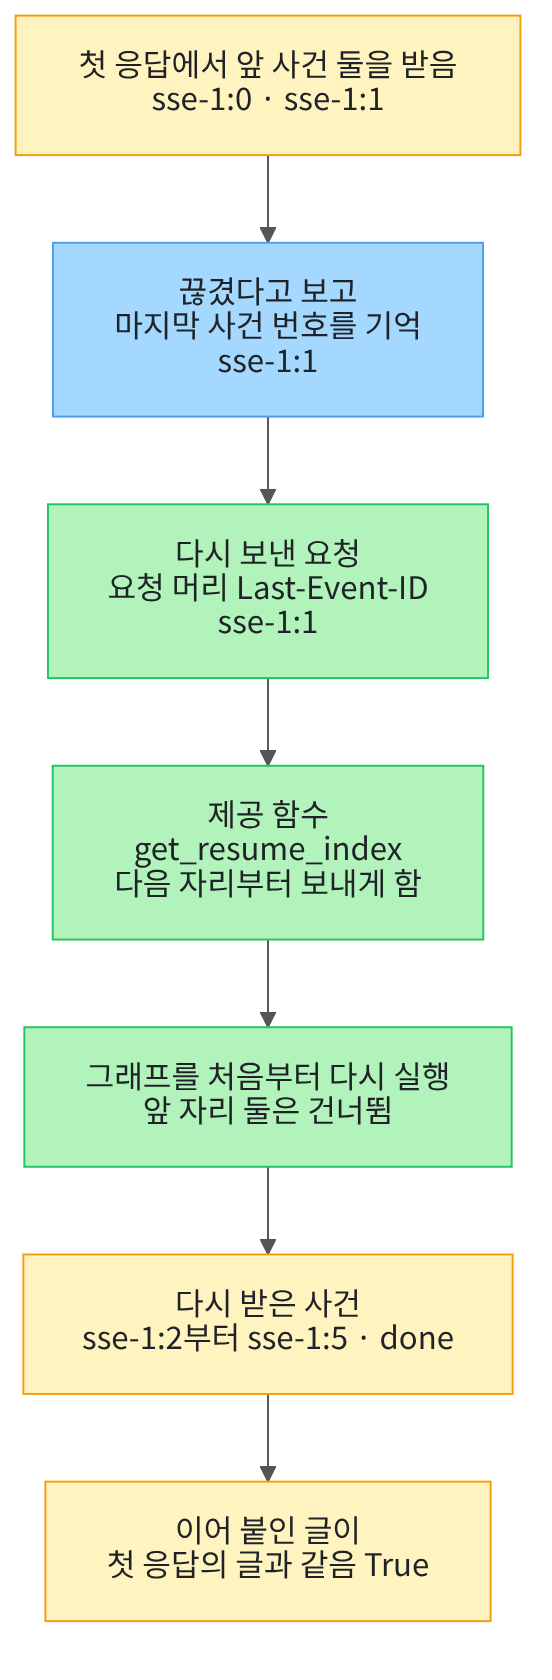

## 1. 준비

05절에서는 처리 함수 `chat_stream`이 보낸 응답 글을 SSE 사건 일곱으로 나눠 읽었습니다.
이 절은 연결이 끊긴 뒤 사건 번호로 이어 받는 방법과, 오류 사건을 받는 쪽의 판정을 봅니다.
제목의 fetch는 브라우저와 Node.js에 들어 있는 함수 이름이고, 4절에서 봅니다.
제목의 재연결은 이 절에서 이어 받기라고 부르고, 제목의 오류 이벤트는 오류 사건이라고 부릅니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `langgraph: 1.2.11`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 05절과 같은 목록입니다.
이 절은 모델 객체를 만들지 않아, API 키를 확인하는 셀도 없습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `logging`은 앱이 남기는 기록을 다룰 때 씁니다.
마지막 가져오기 줄은 앞 절에서 배운 함수 넷을 도구 파일에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·json·logging은 Python에 들어 있는 모듈입니다)
import os
import json
import logging
from fastapi.testclient import TestClient
# 02·04·05절에서 배운 함수 넷은 도구 파일에서 가져옵니다
from serve_tools import join_tokens, parse_sse, split_sse, zero_timeout

print("가져온 이름:", "json, logging, TestClient")
print("도구 파일에서 가져온 함수:", "join_tokens, parse_sse, split_sse, zero_timeout")

가져온 이름: json, logging, TestClient
도구 파일에서 가져온 함수: join_tokens, parse_sse, split_sse, zero_timeout


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: join_tokens, parse_sse, split_sse, zero_timeout`이 보입니다.
함수 `zero_timeout`은 02절, `join_tokens`는 04절, `split_sse`와 `parse_sse`는 05절에서 배웠습니다.
네 함수 모두 그 절 노트북의 셀을 주석과 본문 그대로 옮겼습니다.
도구 파일에는 04절이 옮긴 Ch 25 함수 둘도 있지만, 이 절에서는 쓰지 않습니다.

앞에서 배운 함수는 `serve_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.
실습 폴더 맨 위에서 연 커널은 이 안내를 보기 전에, 앞 셀의 도구 파일 가져오기에서 먼저 멈춥니다.

다음 셀은 05절처럼 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
앱 파일에서 앱 객체 `app`과 시간 제한 제공 함수 `get_timeout`을 가져옵니다.
그래프 파일에서는 에이전트 그래프 `agent`를 가져와, 체크포인터가 있는지 봅니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 그래프·앱 객체·시간 제한 제공 함수를 가져옵니다
os.chdir(lab_path)
from agent_service.agent import agent
from agent_service.app import app, get_timeout
print("가져온 앱 객체의 종류:", type(app).__name__)
print("재정의 딕셔너리의 키 수:", len(app.dependency_overrides))
print("그래프의 체크포인터:", agent.checkpointer)

가져온 앱 객체의 종류: FastAPI
재정의 딕셔너리의 키 수: 0
그래프의 체크포인터: None


**결과 읽기** — 출력 줄 `가져온 앱 객체의 종류: FastAPI`와 `재정의 딕셔너리의 키 수: 0`이 보입니다.
출력 줄 `그래프의 체크포인터: None`은 이 그래프에 체크포인터가 없다는 뜻입니다.
Ch 23 01절의 체크포인터는 스레드마다 상태를 저장했지만, 이 앱은 상태를 저장하지 않습니다.
그래서 요청 본문의 `thread_id`는 사건 번호의 앞머리와 응답 본문에만 쓰입니다.

5절에서는 시간 제한을 넘긴 앱이 오류를 기록합니다.
앱 파일 18행이 만든 기록기는 그 기록을 여러 줄로 표준 오류에 남기고, 기록에는 파일 위치가 들어 있습니다.
다음 셀은 그 기록이 셀 출력에 섞이지 않게, 기록기의 수준을 올립니다.

In [5]:
# 앱의 오류 기록이 셀 출력에 섞이지 않게, 이름이 agent_service.app인 기록기의 수준을 올립니다
app_logger = logging.getLogger("agent_service.app")
app_logger.setLevel(logging.CRITICAL)
print("앱 기록기의 수준:", logging.getLevelName(app_logger.level))

앱 기록기의 수준: CRITICAL


**결과 읽기** — 출력 줄 `앱 기록기의 수준: CRITICAL`이 보입니다.
함수 `logging.getLogger`는 Ch 28 02절에서 본 것처럼, 이름으로 기록기(logger)를 찾아 내놓습니다.
기록기는 정한 수준보다 낮은 기록을 남기지 않고, 이제 가장 높은 수준의 기록만 남깁니다.
앱 120행의 오류 기록은 그보다 낮은 수준이라 셀 출력에 나오지 않습니다.
막은 것은 기록뿐이고, 앱이 보내는 응답은 바뀌지 않습니다.

막지 않으면 5절의 요청 하나에 기록이 25줄 나왔고, 파일 위치가 든 줄도 있었습니다.
줄 수는 노트북 밖의 작은 스크립트로 확인했습니다.

## 2. 첫 응답의 사건 번호

05절에서 본 것처럼 SSE 사건에는 칸 `id`의 사건 번호가 있습니다.
다음 셀은 05절과 같은 질문을 보내고, 상태 코드와 SSE 사건 수를 봅니다.
함수 `split_sse`는 도구 파일에서 가져온 05절 함수입니다.

In [6]:
# 시험용 클라이언트로 05절과 같은 질문을 보내고, 상태 코드와 SSE 사건 수를 봅니다
client = TestClient(app)
auth_headers = {"Authorization": "Bearer local-demo-token"}
question_body = {"question": "반납 기한을 알려 주세요", "thread_id": "sse-1"}
first_response = client.post("/v1/chat/stream", json=question_body, headers=auth_headers)
first_texts = split_sse(first_response.text)
print("상태 코드:", first_response.status_code)
print("SSE 사건 수:", len(first_texts))

상태 코드: 200
SSE 사건 수: 7


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `SSE 사건 수: 7`이 보입니다.
05절과 같은 질문이라, 사건 수도 05절과 같은 일곱입니다.

다음 셀은 응답 본문 글을 받아, SSE 사건마다 칸 딕셔너리로 바꾼 목록을 내놓는 함수를 정의합니다.
05절에서 두 셀로 나눠 했던 일을 함수 하나로 묶습니다.

In [7]:
# 응답 본문 글을 SSE 사건으로 나누고, 사건마다 칸 딕셔너리로 바꾼 목록을 내놓습니다
def read_events(body_text):
    events = []
    for sse_text in split_sse(body_text):
        events.append(parse_sse(sse_text))
    return events

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 안에서 `split_sse`로 사건 글을 나누고, `parse_sse`로 사건마다 칸 딕셔너리를 만듭니다.

다음 셀은 칸 딕셔너리 목록에서 사건 이름만 모아 내놓는 함수를 정의합니다.

In [8]:
# 칸 딕셔너리 목록에서, 사건마다 칸 event의 사건 이름을 모은 목록을 내놓습니다
def event_names(events):
    names = []
    for fields in events:
        names.append(fields["event"])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
받은 사건의 차례를 한 줄로 볼 때 씁니다.

다음 셀은 첫 응답을 읽어, 사건 이름 목록과 첫 사건·마지막 사건의 칸을 출력합니다.

In [9]:
# 첫 응답을 칸 딕셔너리 목록으로 읽고, 사건 이름과 첫 사건·마지막 사건을 출력합니다
first_events = read_events(first_response.text)
print("사건 이름:", event_names(first_events))
print("첫 사건:", first_events[0])
print("마지막 사건:", first_events[-1])

사건 이름: ['token', 'token', 'token', 'token', 'token', 'token', 'done']
첫 사건: {'event': 'token', 'data': '{"token": "\\uc9c8\\ubb38\\uc744 "}', 'id': 'sse-1:0'}
마지막 사건: {'event': 'done', 'data': '{"thread_id": "sse-1"}'}


**결과 읽기** — 출력 줄 `사건 이름: ['token', 'token', 'token', 'token', 'token', 'token', 'done']`이 보입니다.
첫 사건의 칸에는 `'id': 'sse-1:0'`이 있고, 마지막 사건 `done`에는 칸 `id`가 없습니다.
사건 번호는 스레드 이름 `sse-1`과 자리 번호를 쌍점으로 이은 글입니다.

받는 쪽이 이어 받으려면, 마지막으로 받은 사건 번호를 기억해야 합니다.
다음 셀은 칸 딕셔너리 목록에서, 칸 `id`가 있는 마지막 사건의 번호를 내놓는 함수를 정의합니다.

In [10]:
# 칸 딕셔너리 목록에서, 칸 id가 있는 마지막 사건의 번호를 내놓습니다(하나도 없으면 None)
def last_event_id(events):
    found = None
    for fields in events:
        # 번호가 없는 사건(done 등)은 건너뛰어, 앞에서 본 번호를 그대로 둡니다
        if "id" in fields:
            found = fields["id"]
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
번호가 없는 사건을 만나면, 앞에서 본 번호를 그대로 둡니다.
웹 표준 문서인 WHATWG의 HTML 표준도 칸 `id`가 없는 사건은 앞에서 본 번호를 이어 쓴다고 적습니다.

다음 셀은 앞 사건 둘까지 받고 연결이 끊겼다고 보고, 받은 목록과 마지막 번호를 만듭니다.
이 노트북은 연결을 실제로 끊지 않습니다.
시험용 클라이언트는 본문을 끝까지 모아 주므로, 첫 응답 목록의 앞 둘을 받은 사건으로 씁니다.

In [11]:
# 앞 사건 둘까지 받고 연결이 끊겼다고 보고, 받은 목록과 마지막 사건 번호를 만듭니다
received_events = first_events[0:2]
received_last = last_event_id(received_events)
print("받은 사건 이름:", event_names(received_events))
print("받은 마지막 사건 번호:", received_last)
print("첫 응답 전체의 마지막 사건 번호:", last_event_id(first_events))

받은 사건 이름: ['token', 'token']
받은 마지막 사건 번호: sse-1:1
첫 응답 전체의 마지막 사건 번호: sse-1:5


**결과 읽기** — 출력 줄 `받은 사건 이름: ['token', 'token']`과 `받은 마지막 사건 번호: sse-1:1`이 보입니다.
끊기지 않고 끝까지 받았다면, 마지막 번호는 `sse-1:5`입니다.
마지막 사건 `done`에는 번호가 없어, 그 앞 사건의 번호가 남았습니다.

## 3. Last-Event-ID로 이어 받기

이어 받기는 끊긴 뒤 다시 요청할 때, 마지막으로 받은 사건 번호를 함께 보내 그다음 사건부터 받는 일입니다.
책을 덮을 때 책갈피를 꽂아 두고, 다음에 그 쪽부터 펴는 것과 같습니다.
이 앱에서는 요청 머리 `Last-Event-ID`에 그 번호를 적습니다.
다음 셀은 앱 파일에서 이 요청 머리를 읽는 제공 함수의 줄을 출력합니다.

In [12]:
# 앱 파일을 글로 읽어, 요청 머리 Last-Event-ID를 읽는 제공 함수의 41~53행을 출력합니다
first_line = 41
last_line = 53
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_lines = app_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
41 | async def get_resume_index(
42 |     body: ChatRequest,
43 |     last_event_id: Annotated[str | None, Header(alias="Last-Event-ID")] = None,
44 | ) -> int:
45 |     if last_event_id is None:
46 |         return 0
47 |     prefix = f"{body.thread_id}:"
48 |     if not last_event_id.startswith(prefix):
49 |         raise HTTPException(status_code=400, detail="Last-Event-ID의 thread가 다릅니다")
50 |     try:
51 |         return int(last_event_id.removeprefix(prefix)) + 1
52 |     except ValueError as exc:
53 |         raise HTTPException(status_code=400, detail="Last-Event-ID 형식이 올바르지 않습니다") from exc


**결과 읽기** — 라벨 줄 아래 43행의 `Header(alias="Last-Event-ID")`는 요청 머리 `Last-Event-ID`의 값을 이 매개변수에 넣으라는 뜻입니다.
45~46행은 이 요청 머리가 없으면 0을 내놓습니다.
47~49행은 값이 스레드 이름과 쌍점으로 시작하지 않으면, 상태 코드 400으로 멈춥니다.
50~53행은 쌍점 뒤의 글을 수로 바꿔 1을 더하고, 수가 아니면 400으로 멈춥니다.

내놓은 수는 이어 받을 첫 자리이고, 05절에서 본 113행의 `start`가 이 값입니다.
47행은 f-string으로 `sse-1:` 같은 앞머리를 만들고, 51행의 메서드 `removeprefix`는 그 앞머리를 떼어 냅니다.
43행의 `str | None`은 글이거나 없음(`None`)일 수 있다는 힌트이고, `= None`은 요청 머리가 없을 때 쓰는 기본값입니다.
44행 끝의 `-> int`는 내놓는 값이 수라는 힌트입니다.
이 모양들은 이 과정의 노트북에서는 쓰지 않아, 뜻만 봅니다.

다음 셀은 받은 마지막 번호를 요청 머리 `Last-Event-ID`에 적어, 같은 질문을 다시 보냅니다.
요청 머리 딕셔너리에는 02절의 접근 토큰과 이 번호를 함께 적습니다.

In [13]:
# 요청 머리 Last-Event-ID에 받은 마지막 번호를 적어, 같은 질문을 다시 보냅니다
resume_headers = {"Authorization": "Bearer local-demo-token", "Last-Event-ID": received_last}
resumed_response = client.post("/v1/chat/stream", json=question_body, headers=resume_headers)
resumed_events = read_events(resumed_response.text)
print("상태 코드:", resumed_response.status_code)
print("다시 받은 사건 이름:", event_names(resumed_events))
print("다시 받은 첫 사건 번호:", resumed_events[0]["id"])
print("다시 받은 마지막 사건 번호:", last_event_id(resumed_events))

상태 코드: 200
다시 받은 사건 이름: ['token', 'token', 'token', 'token', 'done']
다시 받은 첫 사건 번호: sse-1:2
다시 받은 마지막 사건 번호: sse-1:5


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `다시 받은 첫 사건 번호: sse-1:2`가 보입니다.
사건 이름은 `token` 넷과 `done` 하나이고, 출력 줄 `다시 받은 마지막 사건 번호: sse-1:5`도 보입니다.
이미 받은 두 사건은 다시 오지 않았습니다.

다음 셀은 칸 딕셔너리 목록에서 `token` 사건의 칸 `data`를 읽어 모으는 함수를 정의합니다.
모은 값은 04절의 함수 `join_tokens`로 이어 붙입니다.

In [14]:
# 칸 딕셔너리 목록에서 token 사건만 골라, 칸 data의 JSON 글을 읽은 값의 목록을 내놓습니다
def token_values(events):
    values = []
    for fields in events:
        if fields["event"] == "token":
            values.append(json.loads(fields["data"]))
    return values

**결과 읽기** — 정의 셀이라 출력이 없습니다.
읽은 값 하나는 05절에서 본 `{'token': '질문을 '}` 같은 딕셔너리이고, 04절의 진행 값과 같은 모양입니다.
그래서 04절의 함수 `join_tokens`에 그대로 넣을 수 있습니다.

다음 셀은 끊기기 전에 받은 사건과 다시 받은 사건을 잇고, 칸 `token`의 글을 이어 붙입니다.
끊기지 않은 첫 응답의 글과도 견줍니다.

In [15]:
# 끊기기 전에 받은 사건과 다시 받은 사건을 잇고, 칸 token의 글을 이어 붙입니다
joined_events = received_events + resumed_events
resumed_text = join_tokens(token_values(joined_events))
full_text = join_tokens(token_values(first_events))
print("이은 사건 수:", len(joined_events))
print("이어 붙인 글:", resumed_text)
print("끊기지 않은 첫 응답의 글과 같은가:", resumed_text == full_text)

이은 사건 수: 7
이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 주세요 
끊기지 않은 첫 응답의 글과 같은가: True


**결과 읽기** — 출력 줄 `이은 사건 수: 7`과 `끊기지 않은 첫 응답의 글과 같은가: True`가 보입니다.
이어 붙인 글은 `질문을 확인했습니다: 반납 기한을 알려 주세요`이고, 끝에 공백이 하나 더 있습니다.
04절에서 본 것처럼 노드가 낱말마다 공백을 붙여 적기 때문입니다.

글이 같았던 까닭은 서버 쪽 줄을 보면 드러납니다.
다음 셀은 앱 파일에서, 이어 받을 자리 앞 사건을 건너뛰는 줄을 출력합니다.
3절 앞 셀에서 읽어 둔 앱 파일의 줄 목록을 그대로 씁니다.

In [16]:
# 앱 파일에서, 자리 번호를 0부터 세며 이어 받을 자리 앞 사건을 건너뛰는 107~117행을 출력합니다
first_line = 107
last_line = 117
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
107 |     index = 0
108 |     try:
109 |         async with asyncio.timeout(timeout):
110 |             async for chunk in runtime.astream(
111 |                 {"messages": [body.question]}, stream_mode="custom"
112 |             ):
113 |                 if index >= start:
114 |                     yield ServerSentEvent(
115 |                         data=chunk, event="token", id=_event_id(body.thread_id, index)
116 |                     )
117 |                 index += 1


**결과 읽기** — 라벨 줄 아래 107행 `index = 0`은 요청마다 자리 번호를 0부터 셉니다.
110~112행은 요청마다 그래프의 `astream`을 새로 부릅니다.
113행 `if index >= start:`는 자리 번호가 이어 받을 자리보다 작은 사건을 보내지 않고 건너뜁니다.
117행은 보내든 건너뛰든 자리 번호를 하나 키웁니다.

그래서 이어 받기 요청에도 서버는 그래프를 처음부터 다시 실행합니다.
보낸 사건을 저장해 두었다가 보내는 것이 아니라, 다시 만든 사건 가운데 뒤쪽만 보냅니다.
이 그래프는 모델을 쓰지 않아, 다시 만든 글이 처음 글과 같았습니다.
모델을 부르는 그래프라면 다시 만든 글이 처음 글과 달라질 수 있습니다.
이 노트북에서는 그런 그래프로 실행하지 않았습니다.

그래프 안에 결제처럼 바깥에 쓰는 일이 있다면, 이어 받을 때마다 그 일도 다시 실행됩니다.
Ch 24 01절에서 이어 가는 노드가 첫 줄부터 다시 실행된 것과 같은 모양입니다.
이 그래프에는 바깥 쓰기가 없어, 그 장면은 실행하지 않았습니다.

다음 셀은 요청 머리 `Last-Event-ID` 없이 다시 요청하는 받는 쪽을 봅니다.
끊기기 전에 받은 사건 둘에, 다시 받은 사건을 같은 방법으로 이어 붙입니다.

In [17]:
# 요청 머리 Last-Event-ID 없이 다시 보내고, 받은 사건 둘에 같은 방법으로 이어 붙입니다
plain_response = client.post("/v1/chat/stream", json=question_body, headers=auth_headers)
plain_events = read_events(plain_response.text)
doubled_text = join_tokens(token_values(received_events + plain_events))
print("다시 받은 첫 사건 번호:", plain_events[0]["id"])
print("이어 붙인 글:", doubled_text)
print("끊기지 않은 첫 응답의 글과 같은가:", doubled_text == full_text)

다시 받은 첫 사건 번호: sse-1:0
이어 붙인 글: 질문을 확인했습니다: 질문을 확인했습니다: 반납 기한을 알려 주세요 
끊기지 않은 첫 응답의 글과 같은가: False


**결과 읽기** — 출력 줄 `다시 받은 첫 사건 번호: sse-1:0`과 `끊기지 않은 첫 응답의 글과 같은가: False`가 보입니다.
이어 붙인 글은 `질문을 확인했습니다: 질문을 확인했습니다: 반납 기한을 알려 주세요`로, 앞 두 낱말이 두 번 들어갔습니다.
서버는 처음부터 다시 보냈고, 받는 쪽은 이미 받은 사건 둘에 그것을 또 붙였습니다.

받는 쪽이 번호를 보내지 않으면, 서버는 어디까지 받았는지 모릅니다.
그래서 다시 요청할 때 마지막 번호를 요청 머리에 적습니다.

다음 셀은 요청 머리 `Last-Event-ID`에 값 셋을 차례로 넣어, 서버가 어떻게 답하는지 봅니다.
끝까지 받은 번호 `sse-1:5`, 다른 스레드의 번호 `other:0`, 수가 아닌 번호 `sse-1:x`입니다.

In [18]:
# 요청 머리 Last-Event-ID에 값 셋을 차례로 넣어, 상태 코드와 받은 것을 한 줄씩 봅니다
print("Last-Event-ID | 상태 코드 | 받은 것")
for sent_id in ["sse-1:5", "other:0", "sse-1:x"]:
    edge_headers = {"Authorization": "Bearer local-demo-token", "Last-Event-ID": sent_id}
    edge_response = client.post("/v1/chat/stream", json=question_body, headers=edge_headers)
    if edge_response.status_code == 200:
        edge_events = read_events(edge_response.text)
        print(sent_id, "|", edge_response.status_code, "|", event_names(edge_events))
    else:
        print(sent_id, "|", edge_response.status_code, "|", edge_response.json()["detail"])

Last-Event-ID | 상태 코드 | 받은 것
sse-1:5 | 200 | ['done']
other:0 | 400 | Last-Event-ID의 thread가 다릅니다
sse-1:x | 400 | Last-Event-ID 형식이 올바르지 않습니다


**결과 읽기** — 라벨 줄 아래 첫 줄은 `sse-1:5 | 200 | ['done']`으로, 사건 `done` 하나만 왔습니다.
다른 스레드의 번호는 `other:0 | 400 | Last-Event-ID의 thread가 다릅니다`였습니다.
수가 아닌 번호는 `sse-1:x | 400 | Last-Event-ID 형식이 올바르지 않습니다`였습니다.

400은 41~53행의 제공 함수가 보낸 상태 코드입니다.
설치판 fastapi `routing.py` 452행이 제공 함수를 먼저 부르고, 493행에서야 처리 함수를 부릅니다.
그래서 제공 함수는 응답을 시작하기 전에 400으로 멈출 수 있습니다.
끝까지 받은 번호에는 그래프를 다시 실행하고도 보낼 사건이 없어, `done`만 보냈습니다.

## 4. fetch로 읽는 쪽

지금까지는 파이썬의 시험용 클라이언트로 요청을 보냈습니다.
웹 화면에서는 JavaScript 함수 `fetch`로 같은 요청을 보냅니다.
함수 `fetch`는 브라우저와 Node.js에 들어 있는 함수로, 주소에 요청을 보내고 응답을 받아 줍니다.
편지를 부치고, 답장이 오면 봉투를 열어 읽는 일과 같습니다.
실습 폴더의 TS 파일 `client/stream.ts`가 이 함수로 SSE 사건을 읽습니다.

TS 파일은 JavaScript에 자료형 표시를 더한 TypeScript로 적은 파일입니다.
다음 셀은 그 파일을 글로 읽어, 요청을 보내고 사건을 나누는 11~30행을 출력합니다.

In [19]:
# TS 파일 client/stream.ts를 글로 읽어, 요청을 보내고 사건을 나누는 11~30행을 출력합니다
first_line = 11
last_line = 30
with open("client/stream.ts", encoding="utf-8") as ts_file:
    ts_lines = ts_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", ts_lines[index])

줄 번호 | 줄
11 | export async function* streamChat(question: string, lastEventId?: string) {
12 |   const headers: Record<string, string> = {
13 |     Authorization: "Bearer local-demo-token",
14 |     "Content-Type": "application/json",
15 |   };
16 |   if (lastEventId) headers["Last-Event-ID"] = lastEventId;
17 |   const response = await fetch("http://127.0.0.1:8000/v1/chat/stream", {
18 |     method: "POST",
19 |     headers,
20 |     body: JSON.stringify({ question, thread_id: "web-01" }),
21 |   });
22 |   if (!response.ok || !response.body) throw new Error(`HTTP ${response.status}`);
23 |   const reader = response.body.pipeThrough(new TextDecoderStream()).getReader();
24 |   let buffer = "";
25 |   for (;;) {
26 |     const { value, done } = await reader.read();
27 |     buffer += value ?? "";
28 |     const blocks = buffer.split(/\r?\n\r?\n/);
29 |     buffer = blocks.pop() ?? "";
30 |     for (const block of blocks) yield decodeBlock(block);


**결과 읽기** — 라벨 줄 아래 16행은 `if (lastEventId) headers["Last-Event-ID"] = lastEventId;`입니다.
이어 받을 번호가 있으면 요청 머리 `Last-Event-ID`에 적는 줄로, 3절에서 파이썬으로 한 일과 같습니다.
17~21행은 함수 `fetch`로 요청 방식 POST와 요청 머리, 요청 본문을 보냅니다.
22행은 `response.ok`가 거짓이면 멈추고, 이 값은 상태 코드가 200대인지를 뜻합니다.
28~29행은 받은 글을 빈 줄에서 나누고, 빈 줄로 끝나지 않은 끝 글은 남겨 둡니다.

네트워크로 받는 본문은 여러 번에 나뉘어 오고, 나뉜 자리가 SSE 사건의 경계와 다를 수 있습니다.
그래서 29행이 남긴 끝 글은 다음에 받은 글 앞에 붙습니다.
이 절의 시험용 클라이언트는 본문을 끝까지 모아 주어, 이런 나뉨이 없었습니다.
28행은 줄 끝이 `\r\n`인 글도 나누지만, 05절의 함수 `split_sse`는 `\n\n`만 봅니다.
30행의 함수 `decodeBlock`은 3~9행에 있고, 사건 글에서 칸 셋의 첫 줄을 읽습니다.

이 파일은 README에 적힌 명령으로, 서버를 띄운 뒤 실행하는 파일입니다.
이 노트북에서는 실행하지 않았고, 실행하는 명령은 실습 폴더 `README.md`에 있습니다.

## 5. 상태 코드만 보는 판정 (Before)

SSE 응답은 본문을 보내기 전에 상태 코드부터 보냅니다.
설치판 starlette `responses.py` 249행이 본문의 첫 사건을 꺼내기 전에 상태 코드를 보냅니다.
그래서 처리 함수 안에서 오류가 나도, 받는 쪽이 받은 상태 코드는 이미 200입니다.
앱 119~124행은 그 오류를 받아, 사건 이름이 `error`인 SSE 사건을 보냅니다.

오류 사건은 사건 이름이 `error`인 SSE 사건입니다.
주문 앱이 주문 접수를 먼저 알린 뒤, 재료가 떨어지면 주문 취소를 따로 알리는 것과 같습니다.
이 앱의 오류 사건은 칸 `data`에 `stream_failed` 같은 오류 코드를 담습니다.

Before 판에서 받는 쪽은 상태 코드만 보고 성공인지 판정합니다.
다음 셀은 그 판정 함수를 정의합니다.

In [20]:
# Before 판정: 응답의 상태 코드만 보고, 200이면 성공으로 셉니다
def status_says_ok(response):
    return response.status_code == 200

**결과 읽기** — 정의 셀이라 출력이 없습니다.
응답 본문의 사건은 보지 않고, 상태 코드가 200인지만 봅니다.

다음 셀은 시간 제한을 0초로 재정의하고, 2절과 같은 질문을 보냅니다.
재정의 함수 `zero_timeout`은 02절 함수이고, 도구 파일에서 가져왔습니다.
02절에서 본 것처럼 재정의는 앱 객체에 남으므로, 같은 셀 안에서 재정의 딕셔너리를 비웁니다.
시간 제한 0초는 정한 초가 아주 짧은 경우로, 실제로 일어날 수 있는 조건입니다.

In [21]:
# 시간 제한을 0초로 재정의해 같은 질문을 보내고, 같은 셀에서 재정의 딕셔너리를 비웁니다
app.dependency_overrides[get_timeout] = zero_timeout
zero_seconds = await zero_timeout()
zero_response = client.post("/v1/chat/stream", json=question_body, headers=auth_headers)
app.dependency_overrides.clear()
print("재정의한 함수가 내놓는 초:", zero_seconds)
print("상태 코드:", zero_response.status_code)
print("본문 종류:", zero_response.headers["content-type"])
print("비운 뒤 재정의 딕셔너리의 키 수:", len(app.dependency_overrides))

재정의한 함수가 내놓는 초: 0.0
상태 코드: 200
본문 종류: text/event-stream; charset=utf-8
비운 뒤 재정의 딕셔너리의 키 수: 0


**결과 읽기** — 출력 줄 `재정의한 함수가 내놓는 초: 0.0`과 `상태 코드: 200`이 보입니다.
본문 종류도 `text/event-stream; charset=utf-8`로 2절과 같습니다.
출력 줄 `비운 뒤 재정의 딕셔너리의 키 수: 0`으로, 재정의가 남지 않은 것도 확인했습니다.

앱 109행의 `asyncio.timeout`은 05절에서 풀이만 하고 실행하지 않은 줄입니다.
설치판 Python 3.12.13 `asyncio/timeouts.py` 68~69행은 정한 때가 이미 지났으면 곧바로 취소를 겁니다.
그 취소는 112~115행에서 오류 `TimeoutError`로 바뀌고, 앱 119행이 그 오류를 받습니다.

다음 셀은 상태 코드만 본 판정과, 실제로 받은 SSE 사건을 함께 출력합니다.
실행 전에 예상해 봅니다.
상태 코드가 200이니, 답의 글도 모두 왔을까요?

In [22]:
# 상태 코드만 본 판정과, 실제로 받은 SSE 사건을 함께 출력합니다
zero_events = read_events(zero_response.text)
print("상태 코드만 본 판정(성공인가):", status_says_ok(zero_response))
zero_tokens = token_values(zero_events)
print("받은 사건 이름:", event_names(zero_events))
print("받은 token 사건 수:", len(zero_tokens))

상태 코드만 본 판정(성공인가): True
받은 사건 이름: ['error']
받은 token 사건 수: 0


**결과 읽기** — 출력 줄 `상태 코드만 본 판정(성공인가): True`가 보입니다.
그런데 받은 사건 이름은 `['error']` 하나뿐이고, 출력 줄 `받은 token 사건 수: 0`도 보입니다.
답의 글은 한 낱말도 오지 않았고, 끝을 알리는 `done`도 없었습니다.
그래도 Before 판정은 이 응답을 성공으로 셉니다.
이것이 이 절의 Before 결함입니다.

다음 셀은 받은 사건 하나의 칸을 보고, 칸 `data`의 JSON 글을 읽습니다.

In [23]:
# 받은 사건 하나의 칸 이름을 출력하고, 칸 data의 JSON 글을 읽습니다
error_fields = zero_events[0]
print("받은 사건의 칸 이름:", list(error_fields))
error_value = json.loads(error_fields["data"])
print("칸 data를 읽은 값:", error_value)

받은 사건의 칸 이름: ['event', 'data']
칸 data를 읽은 값: {'code': 'stream_failed', 'message': 'Agent 스트림이 중단되었습니다'}


**결과 읽기** — 출력 줄 `받은 사건의 칸 이름: ['event', 'data']`가 보입니다.
오류 사건에는 칸 `id`가 없어, 이 사건으로는 이어 받을 번호가 생기지 않습니다.
칸 `data`를 읽은 값은 `{'code': 'stream_failed', 'message': 'Agent 스트림이 중단되었습니다'}`입니다.
앱 121~124행이 적은 오류 코드와 알림 글입니다.

## 6. 마지막 사건을 보는 판정 (After)

After 판에서 받는 쪽은 마지막 SSE 사건의 이름이 `done`인지 봅니다.
앱 118행은 그래프의 사건을 끝까지 보낸 뒤에만 `done`을 보냅니다.
오류 사건으로 끝났거나 사건이 하나도 없으면, 끝까지 받지 못한 것입니다.
다음 셀은 그 판정 함수를 정의합니다.

In [24]:
# After 판정: 칸 딕셔너리 목록에서 마지막 사건의 이름이 done인지 봅니다
def ended_with_done(events):
    # 사건이 하나도 없으면 끝까지 받지 못한 것으로 셉니다
    if len(events) == 0:
        return False
    last_fields = events[-1]
    return last_fields["event"] == "done"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
목록이 비었는지 먼저 보는 까닭은, 빈 목록에서 끝 사건을 꺼내면 오류가 나기 때문입니다.

다음 셀은 5절의 0초 응답과 2절의 첫 응답을, 두 판정으로 함께 봅니다.

In [25]:
# 0초 응답과 첫 응답을, Before 판정과 After 판정으로 함께 봅니다
print("응답 | 상태 코드만 본 판정 | 마지막 사건이 done인가")
print("0초 응답 |", status_says_ok(zero_response), "|", ended_with_done(zero_events))
print("첫 응답 |", status_says_ok(first_response), "|", ended_with_done(first_events))

응답 | 상태 코드만 본 판정 | 마지막 사건이 done인가
0초 응답 | True | False
첫 응답 | True | True


**결과 읽기** — 라벨 줄 아래 첫 줄은 `0초 응답 | True | False`입니다.
상태 코드만 본 판정은 성공이라 했지만, After 판정은 끝까지 받지 못했다고 봅니다.
둘째 줄 `첫 응답 | True | True`에서는 두 판정이 같습니다.
After 판정은 끝까지 받은 응답을 실패로 잘못 세지 않았습니다.

끝까지 받지 못했다고 보면, 받는 쪽은 칸 `code`를 보고 다음 일을 정합니다.
연결이 끊긴 것이면 마지막 번호로 이어 받고, 오류 사건이면 사용자에게 알리는 식입니다.
이 노트북에서는 그 다음 일을 실행하지 않았습니다.

## 7. 값 바꿔 보기: 범위 밖 사건 번호

값 하나만 바꿔 봅니다.
바꿀 것은 요청 머리 `Last-Event-ID`의 값이고, 3절의 `sse-1:1` 대신 범위 밖 번호 `sse-1:99`를 넣습니다.
이 질문의 사건 번호는 `sse-1:5`까지뿐입니다.
실행 전에 예상해 봅니다.
After 판정은 이 응답을 어떻게 볼까요?

In [26]:
# 요청 머리 Last-Event-ID만 범위 밖 번호 sse-1:99로 바꿔 보내고, After 판정으로 봅니다
far_headers = {"Authorization": "Bearer local-demo-token", "Last-Event-ID": "sse-1:99"}
far_response = client.post("/v1/chat/stream", json=question_body, headers=far_headers)
far_events = read_events(far_response.text)
print("상태 코드:", far_response.status_code)
print("받은 사건 이름:", event_names(far_events))
far_tokens = token_values(far_events)
print("마지막 사건이 done인가:", ended_with_done(far_events))
print("받은 token 사건 수:", len(far_tokens))

상태 코드: 200
받은 사건 이름: ['done']
마지막 사건이 done인가: True
받은 token 사건 수: 0


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `받은 사건 이름: ['done']`이 보입니다.
출력 줄 `마지막 사건이 done인가: True`와 `받은 token 사건 수: 0`도 보입니다.
서버는 범위 밖 번호를 검사하지 않고, 그래프를 끝까지 실행한 뒤 `done`만 보냈습니다.
그래서 After 판정은 글을 한 낱말도 받지 않은 이 응답도 끝까지 받았다고 봅니다.

3절에서 끝까지 받은 번호 `sse-1:5`를 보냈을 때도 `done`만 왔습니다.
받는 쪽에서 보면 두 응답은 모양이 같습니다.
After 판정은 오류 사건과 끝까지 받은 응답을 가를 뿐, 보낸 번호가 맞는지까지 보지는 못합니다.
번호가 이 질문의 범위 안인지는 서버의 제공 함수가 검사해야 하고, 이 앱은 그 검사를 하지 않습니다.

## 정리

1. 요청 머리 `Last-Event-ID`에 받은 마지막 번호를 적자, 서버가 다음 번호부터 보내 이어 붙인 글이 처음 글과 같았습니다.
2. 시간 제한 0초 응답은 상태 코드 200이었지만 사건은 `error` 하나뿐이라, 상태 코드만 본 판정은 틀렸습니다.
3. 마지막 사건이 `done`인지 보는 판정은 이 응답을 가려냈지만, 범위 밖 번호에 온 `done`까지 가리지는 못했습니다.

07절에서는 접근 토큰 검사와 다른 출처의 요청을 다루는 설정, 시간 제한을 함께 봅니다.